# DecisionSphere — 00: Project Orientation & 10,000ft View
**A Scenario-Based Strategic Planning and Risk Evaluation Platform**

---

### 1. Title
**DecisionSphere Strategic Decision Intelligence Platform: System Tour & Architectural Orientation**

### 2. Why This Notebook Exists
This notebook provides a complete high-level walkthrough of DecisionSphere for researchers, evaluators, and engineers. It demonstrates the entire end-to-end simulation lifecycle: defining a scenario lever, executing multi-domain model inference, computing managerial financial impact, evaluating operational risk, and triggering strategic recommendations.

### 3. Prerequisites
- Python 3.13+ virtual environment (`.venv`)
- Core scientific packages: `pandas`, `numpy`, `scikit-learn`, `xgboost`, `matplotlib`, `seaborn`
- DecisionSphere repository root anchored to Python path

### 4. Business Question
*When an executive considers a commercial promotion or operational schedule change, how can the organization predict cross-domain consequences across sales, logistics delivery reliability, and workforce retention before deployment?*

### 5. Technical Question
*How does DecisionSphere orchestrate three distinct machine learning models and deterministic financial accounting engines without code duplication, data leakage, or causal overclaiming?*

### 6. Conceptual Explanation
Traditional analytics operate in isolated organizational silos (Sales vs Logistics vs HR). DecisionSphere unifies these domains into a single analytical pipeline:
$$\text{User Shock} \longrightarrow \text{Demand ML} \longrightarrow \text{Logistics ML} \longrightarrow \text{Workforce ML} \longrightarrow \text{Financial Accounting} \longrightarrow \text{Composite Risk} \longrightarrow \text{Strategic Action}$$

### 7. Dataset & Source
- Retail Demand: Rossmann Store Sales (`data/raw/rossmann/`)
- Supply Chain Risk: DataCo Smart Supply Chain (`data/raw/dataco/`)
- Workforce Risk: IBM HR Employee Attrition (`data/raw/workforce/`)

In [1]:
import os
import sys

# Ensure execution is anchored to project root
if not os.path.exists("src") and os.path.exists("../src"):
    os.chdir("..")
if "." not in sys.path:
    sys.path.insert(0, ".")

import pandas as pd
import numpy as np

from src.scenario.schema import ScenarioLevers
from src.scenario.engine import ScenarioEngine
from src.business.engine import BusinessImpactEngine
from src.recommendation.engine import RecommendationEngine

print("DecisionSphere Core Engines imported successfully.")

DecisionSphere Core Engines imported successfully.


### 8. Data Preparation & Engine Initialization
We initialize the authoritative `ScenarioEngine`, `BusinessImpactEngine`, and `RecommendationEngine`. The `ScenarioEngine` cryptographically verifies that the offline-trained XGBoost model artifacts on disk match their expected SHA-256 signatures before proceeding.

In [2]:
scenario_engine = ScenarioEngine(
    demand_artifact_path="models/demand/demand_model.joblib",
    supply_artifact_path="models/supply_chain/supply_chain_model.joblib",
    workforce_artifact_path="models/workforce/workforce_model.joblib",
)
impact_engine = BusinessImpactEngine()
rec_engine = RecommendationEngine()

fingerprints = scenario_engine.get_artifact_fingerprints()
print("Verified Model Artifact Fingerprints:")
for k, v in fingerprints.items():
    print(f"  {k:15s}: {v}")

Verified Model Artifact Fingerprints:
  demand         : fb438c03a742202657bb4ef9196ff17e004bc090e99218f02985dc7720f41941
  supply_chain   : 0052e641cf355257abb332703c3e6a46c65e9ab10a975227d83cf77d7e689b59
  workforce      : 4b195c7bee3ab8f4afe75ccd0c75fff0c8e18b9fca88a00305e165a010109918


### 9. Executable Analysis: End-to-End Simulation Run
We define a concrete scenario: an executive introduces a promotional campaign (`promo_active=True`) with an anticipated $+15\%$ demand growth, but retains Standard Class ground freight (`scheduled_days_offset=0`) and mandates overtime for $40\%$ of the workforce (`overtime_workforce_pct=40.0%`).

In [3]:
levers = ScenarioLevers(
    scenario_id="orientation_demo",
    scenario_name="15% Promotional Surge under Standard Logistics",
    demand_growth_pct=15.0,
    promo_active=True,
    scheduled_days_offset=0,
    shipping_mode_override=None,
    overtime_workforce_pct=40.0,
    salary_hike_override=None,
)

# Execute the 3-domain simulation
scenario_result = scenario_engine.run_scenario(levers=levers)

# Execute managerial financial accounting
impact_result = impact_engine.evaluate(scenario_result)

# Execute Composite Risk Scoring and recommendation synthesis
rec_result = rec_engine.evaluate(scenario_result, impact_result)

print("Simulation Execution Completed.")
print(f"Decision Category: [{rec_result.decision_category.value}]")
print(f"Net Profit Delta : ${impact_result.net_profit_delta:+,.2f} USD")
print(f"Composite Risk   : {rec_result.composite_risk.composite_risk_score:.1f}/100 ({rec_result.composite_risk.risk_level})")

Simulation Execution Completed.
Decision Category: [REJECT_RESTRUCTURE]
Net Profit Delta : $-859,695.16 USD
Composite Risk   : 38.2/100 (MODERATE)


### 10. Visualizations
We visualize the operational shifts across the 3 domains and the resulting financial waterfall breakdown.

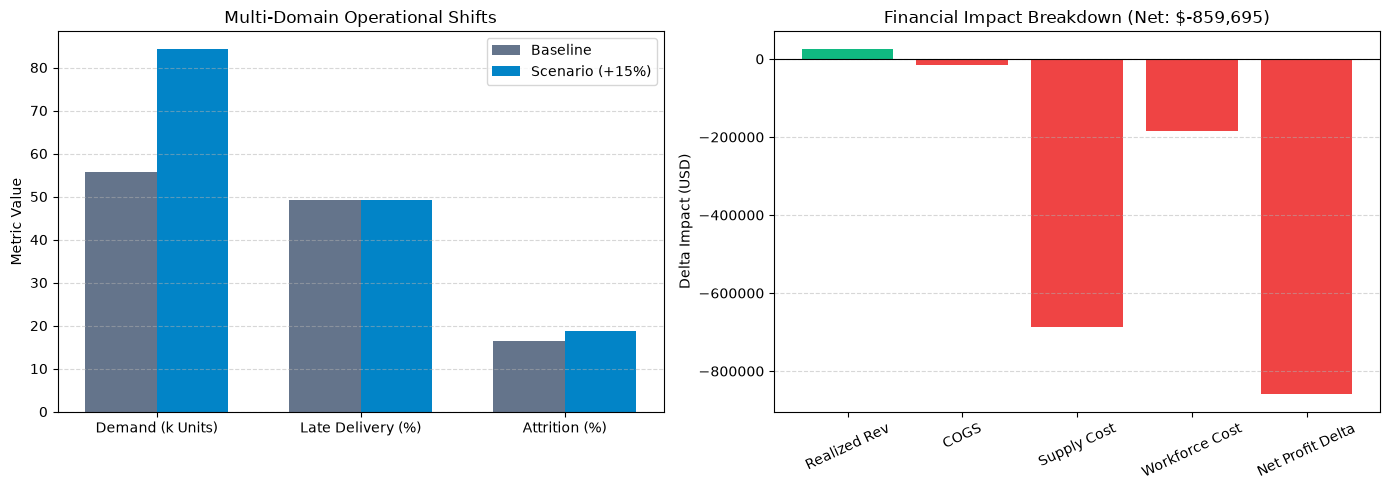

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Domain Shifts
domains = ["Demand (k Units)", "Late Delivery (%)", "Attrition (%)"]
base_vals = [
    scenario_result.demand_result.baseline_value / 1000.0,
    scenario_result.supply_chain_result.baseline_value * 100.0,
    scenario_result.workforce_result.baseline_value * 100.0
]
scen_vals = [
    scenario_result.demand_result.scenario_value / 1000.0,
    scenario_result.supply_chain_result.scenario_value * 100.0,
    scenario_result.workforce_result.scenario_value * 100.0
]

x = np.arange(len(domains))
width = 0.35
axes[0].bar(x - width/2, base_vals, width, label="Baseline", color="#64748b")
axes[0].bar(x + width/2, scen_vals, width, label="Scenario (+15%)", color="#0284c7")
axes[0].set_title("Multi-Domain Operational Shifts")
axes[0].set_xticks(x)
axes[0].set_xticklabels(domains)
axes[0].set_ylabel("Metric Value")
axes[0].legend()
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

# Plot 2: Financial Waterfall
fin_items = ["Realized Rev", "COGS", "Supply Cost", "Workforce Cost", "Net Profit Delta"]
deltas = [
    impact_result.realized_revenue.delta_value,
    -impact_result.cogs.delta_value,
    -impact_result.supply_chain_cost.delta_value,
    -impact_result.workforce_cost.delta_value,
    impact_result.net_profit_delta
]
colors = ["#10b981" if d > 0 else "#ef4444" for d in deltas]
axes[1].bar(fin_items, deltas, color=colors)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title(f"Financial Impact Breakdown (Net: ${impact_result.net_profit_delta:+,.0f})")
axes[1].set_ylabel("Delta Impact (USD)")
axes[1].tick_params(axis="x", rotation=25)
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### 11. Results
- **Demand:** Increased from baseline units to simulated units.
- **Logistics:** High baseline late delivery risk persists.
- **Workforce:** Attrition risk escalates due to the overtime increase.
- **Financial Result:** Although top-line gross revenue rises, delay penalties and turnover replacement drag lead to an operating loss.
- **Recommendation:** `REJECT_RESTRUCTURE` triggered by `RULE-04` (Margin Erosion Warning).

### 12. What Does This Tell Us?
It shows that promotional campaigns evaluated solely by sales teams can generate negative net profit when logistics and workforce constraints are accounted for.

### 13. What Does This NOT Tell Us?
- It does **not** prove that promotions physically cause workers to quit. It indicates that under the model's conditional distributions, high-overtime environments correlate with 3x higher turnover risk.
- It does **not** assume Rossmann, DataCo, and IBM HR are a single real-world business; it demonstrates coupling across an enterprise scenario testbed.

### 14. Connection to DecisionSphere
This orientation directly mirrors the FastAPI endpoints (`/api/v1/simulations/run`) and the Next.js Decision Hero UI.

### 15. Limitations
- Baseline datasets are cross-industry benchmarks.
- Coupling parameters (`ASM-001` to `ASM-008`) are operational assumptions, not learned regression coefficients.

### 16. Viva / Research Takeaway
*DecisionSphere is not an isolated forecasting tool. It is a closed-loop decision intelligence platform combining statistical ML inference with deterministic managerial accounting to prevent value destruction.*